# Morocco Electricity Consumption Analysis
## Week 5 - Data Analytics Track - Tasks 1 to 6

This notebook completes Tasks 1-6 of the Week 5 Data Analytics assignment. It uses Pandas and NumPy for inspection and preparation, Matplotlib and Seaborn for static charts, SciPy for rank correlations, and Plotly for interactive charts.

**Measurement caution:** The supplied dictionary labels the zone fields in kWh but does not establish whether a 10-minute value is interval energy or a power reading. All comparisons below use the **mean reported observation value** and avoid summing readings into energy totals until the data owner confirms the unit semantics. Correlation is descriptive and is not evidence of causation.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.stats import spearmanr, pearsonr
from IPython.display import display

# Locate data from either the project root or the notebooks/ folder.
HERE = Path.cwd()
BASE = HERE.parent if HERE.name == "notebooks" else HERE
DATA_PATH = BASE / "data" / "powerconsumption.csv"
DICT_PATH = BASE / "data" / "powerconsumption_datadictionary.csv"
VIS_DIR = BASE / "visualizations"
VIS_DIR.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(DATA_PATH)
data_dictionary = pd.read_csv(DICT_PATH)
zone_cols = ["PowerConsumption_Zone1", "PowerConsumption_Zone2", "PowerConsumption_Zone3"]
zone_labels = {c: c.replace("PowerConsumption_", "").replace("_", " ") for c in zone_cols}
env_cols = ["Temperature", "Humidity", "WindSpeed"]
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
print(f"Loaded {len(raw):,} rows and {len(raw.columns)} columns from {DATA_PATH.name}.")


Loaded 52,416 rows and 9 columns from powerconsumption.csv.


## Task 1 - Dataset Understanding and Inspection

The first section checks the source structure, field definitions, missingness, duplicate rows and timestamps, numeric validity, datetime conversion, chronological order and ten-minute cadence. The data dictionary is descriptive reference information; unresolved measurement meanings are recorded for follow-up.

In [2]:
print("Shape:", raw.shape)
print("Columns:", list(raw.columns))
print("Imported data types:")
print(raw.dtypes.to_string())
print("\nFirst five records:")
display(raw.head())
print("\nSupplied data dictionary:")
display(data_dictionary)


Shape: (52416, 9)
Columns: ['Datetime', 'Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']
Imported data types:
Datetime                   object
Temperature               float64
Humidity                  float64
WindSpeed                 float64
GeneralDiffuseFlows       float64
DiffuseFlows              float64
PowerConsumption_Zone1    float64
PowerConsumption_Zone2    float64
PowerConsumption_Zone3    float64

First five records:
        Datetime  Temperature  Humidity  WindSpeed  GeneralDiffuseFlows  DiffuseFlows  PowerConsumption_Zone1  PowerConsumption_Zone2  PowerConsumption_Zone3
0  1/1/2017 0:00        6.559      73.8      0.083                0.051         0.119             34055.69620             16128.87538             20240.96386
1  1/1/2017 0:10        6.414      74.5      0.083                0.070         0.085             29814.68354             19375.07599      

In [3]:
missing = raw.isna().sum().rename("missing_count").to_frame()
missing["missing_pct"] = (missing.missing_count / len(raw) * 100).round(3)
print("Missing values by field:")
display(missing)
print("Full duplicate rows:", int(raw.duplicated().sum()))
print("Duplicate Datetime values:", int(raw["Datetime"].duplicated().sum()))

num_check = raw.drop(columns="Datetime").apply(pd.to_numeric, errors="coerce")
print("Numeric parse failures:")
display(num_check.isna().sum().rename("parse_failures").to_frame())
print("Negative numeric readings:", int((num_check < 0).sum().sum()))
print("Infinite numeric readings:", int(np.isinf(num_check).sum().sum()))


Missing values by field:
                        missing_count  missing_pct
Datetime                            0          0.0
Temperature                         0          0.0
Humidity                            0          0.0
WindSpeed                           0          0.0
GeneralDiffuseFlows                 0          0.0
DiffuseFlows                        0          0.0
PowerConsumption_Zone1              0          0.0
PowerConsumption_Zone2              0          0.0
PowerConsumption_Zone3              0          0.0
Full duplicate rows: 0
Duplicate Datetime values: 0
Numeric parse failures:
                        parse_failures
Temperature                          0
Humidity                             0
WindSpeed                            0
GeneralDiffuseFlows                  0
DiffuseFlows                         0
PowerConsumption_Zone1               0
PowerConsumption_Zone2               0
PowerConsumption_Zone3               0
Negative numeric readings: 0
Infinite 

In [4]:
# Parse timestamps in an analysis copy, leaving `raw` and the source CSV unchanged.
inspection = raw.copy()
inspection["Datetime"] = pd.to_datetime(inspection["Datetime"], errors="coerce")
ordered = inspection["Datetime"].dropna().sort_values()
deltas = ordered.diff().dropna()
expected = pd.date_range(ordered.min(), ordered.max(), freq="10min")
observed = pd.DatetimeIndex(ordered.unique())
missing_times = expected.difference(observed)
daily_n = ordered.dt.normalize().value_counts()
print("Datetime parse failures:", int(inspection.Datetime.isna().sum()))
print("Datetime range:", ordered.min(), "to", ordered.max())
print("Source sorted chronologically:", bool(inspection.Datetime.is_monotonic_increasing))
print("Observed interval frequencies:")
print(deltas.value_counts().to_string())
print("Intervals other than 10 minutes:", int((deltas != pd.Timedelta(minutes=10)).sum()))
print("Missing expected timestamps within observed range:", len(missing_times))
print("Observed dates:", daily_n.size, "readings per day min/max:", int(daily_n.min()), int(daily_n.max()))


Datetime parse failures: 0
Datetime range: 2017-01-01 00:00:00 to 2017-12-30 23:50:00
Source sorted chronologically: True
Observed interval frequencies:
Datetime
0 days 00:10:00    52415
Intervals other than 10 minutes: 0
Missing expected timestamps within observed range: 0
Observed dates: 364 readings per day min/max: 144 144


**Inspection note:** The timestamps span 2017-01-01 00:00 through 2017-12-30 23:50. There are 364 observed dates at 144 readings per date and no cadence gaps inside that observed range. December 31 is not present, so the extract is not a full 365-day calendar year. The data dictionary's units for zone consumption and physical descriptions of `GeneralDiffuseFlows` / `DiffuseFlows` need confirmation before energy totals or environmental interpretations are made.

## Task 2 - Data Cleaning and Preparation

No imputation or row removal is needed based on the inspection: there are no missing cells, duplicate timestamps, duplicate full rows, or invalid parsed values. Datetime is converted to pandas datetime, and the required time features are added. Statistical IQR flags are reviewed but retained because flags alone do not prove erroneous readings.

In [5]:
df = inspection.copy()
df["Year"] = df.Datetime.dt.year
df["Month"] = df.Datetime.dt.month
df["MonthName"] = df.Datetime.dt.month_name()
df["Day"] = df.Datetime.dt.day
df["Hour"] = df.Datetime.dt.hour
df["DayOfWeek"] = df.Datetime.dt.day_name()
df["Date"] = df.Datetime.dt.date
# Report Tukey 1.5*IQR upper/lower flags by zone; do not delete flagged rows.
outlier_rows = []
for col in zone_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = (df[col] < low) | (df[col] > high)
    outlier_rows.append({"Zone": zone_labels[col], "lower_fence": low, "upper_fence": high,
                         "flagged_count": int(flagged.sum()), "flagged_pct": flagged.mean() * 100,
                         "above_upper": int((df[col] > high).sum())})
outlier_summary = pd.DataFrame(outlier_rows).set_index("Zone")
display(outlier_summary.round(3))


       lower_fence  upper_fence  flagged_count  flagged_pct  above_upper
Zone                                                                    
Zone1     9813.144    53806.542              0        0.000            0
Zone2     5381.339    36313.145              7        0.013            7
Zone3      387.166    34366.261           1191        2.272         1191


In [6]:
# Check where statistical high flags occur, to assess whether they cluster in known time patterns.
flag_months = {}
for col in zone_cols:
    q1, q3 = df[col].quantile([0.25, 0.75]); high = q3 + 1.5 * (q3 - q1)
    flagged = df.loc[df[col] > high, "Datetime"]
    flag_months[zone_labels[col]] = flagged.dt.month.value_counts().sort_index().to_dict()
print("Months containing upper-fence flags:", flag_months)

clean_path = BASE / "data" / "powerconsumption_cleaned.csv"
df.to_csv(clean_path, index=False)
print(f"Prepared data saved to {clean_path.name} ({len(df):,} rows; no rows dropped).")
print("Added time fields: Year, Month, MonthName, Day, Hour, DayOfWeek, Date")


Months containing upper-fence flags: {'Zone1': {}, 'Zone2': {7: 2, 8: 5}, 'Zone3': {7: 760, 8: 431}}
Prepared data saved to powerconsumption_cleaned.csv (52,416 rows; no rows dropped).
Added time fields: Year, Month, MonthName, Day, Hour, DayOfWeek, Date


## Task 3 - Electricity Consumption Analysis

Since the unit-per-interval interpretation is not confirmed, summaries below use **mean reported values** rather than sums. Daily, weekly, monthly, hourly and day-of-week summaries show typical observation levels, and peak rows identify observed maxima.

In [7]:
stats = df[zone_cols].agg(["count", "mean", "median", "std", "var", "min", "max"]).T
stats["q1"] = df[zone_cols].quantile(.25)
stats["q3"] = df[zone_cols].quantile(.75)
stats["iqr"] = stats.q3 - stats.q1
stats = stats.rename(index=zone_labels)
print("Descriptive statistics by zone (reported observation values):")
display(stats.round(3))
print("\nMean ranking:")
display(stats[["mean"]].sort_values("mean", ascending=False).round(2))


Descriptive statistics by zone (reported observation values):
         count       mean     median       std           var        min        max         q1         q3        iqr
Zone1  52416.0  32344.971  32265.920  7130.563  5.084492e+07  13895.696  52204.395  26310.669  37309.018  10998.349
Zone2  52416.0  21042.509  20823.168  5201.466  2.705525e+07   8560.081  37408.861  16980.766  24713.718   7732.951
Zone3  52416.0  17835.406  16415.117  6622.165  4.385307e+07   5935.174  47598.326  13129.327  21624.100   8494.774

Mean ranking:
           mean
Zone1  32344.97
Zone2  21042.51
Zone3  17835.41


In [8]:
daily = df.groupby("Date")[zone_cols].mean()
weekly = df.set_index("Datetime")[zone_cols].resample("W-MON").mean()
monthly = df.groupby("Month")[zone_cols].mean()
hourly = df.groupby("Hour")[zone_cols].mean()
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = df.groupby("DayOfWeek")[zone_cols].mean().reindex(dow_order)
weekday_weekend = df.assign(DayType=np.where(df.Datetime.dt.dayofweek < 5, "Weekday", "Weekend")).groupby("DayType")[zone_cols].mean()

print("Highest and lowest mean hours by zone:")
display(pd.DataFrame({z:{"peak_hour":int(hourly[z].idxmax()),"peak_hour_mean":hourly[z].max(),"lowest_hour":int(hourly[z].idxmin()),"lowest_hour_mean":hourly[z].min()} for z in zone_cols}).T.rename(index=zone_labels).round(2))
print("Monthly mean by zone:")
display(monthly.rename(columns=zone_labels).round(2))
print("Day-of-week mean by zone:")
display(dow.rename(columns=zone_labels).round(2))
print("Weekday vs weekend means:")
display(weekday_weekend.rename(columns=zone_labels).round(2))


Highest and lowest mean hours by zone:
       peak_hour  peak_hour_mean  lowest_hour  lowest_hour_mean
Zone1       20.0        43822.59          6.0          23203.60
Zone2       20.0        28186.91          6.0          14934.70
Zone3       20.0        26027.61          7.0          11667.86
Monthly mean by zone:
          Zone1     Zone2     Zone3
Month                              
1      31032.49  19394.44  17746.10
2      30985.75  18787.79  17335.00
3      31155.17  18457.94  16947.69
4      31169.77  17633.97  18593.17
5      32396.01  19977.29  17621.10
6      34605.54  20670.93  20430.94
7      35831.55  24147.89  28194.11
8      36435.19  24656.22  24648.89
9      33396.68  20180.43  14922.80
10     32827.66  21468.99  13264.10
11     29002.11  23240.46  12862.50
12     29024.17  23681.85  11044.81
Day-of-week mean by zone:
              Zone1     Zone2     Zone3
DayOfWeek                              
Monday     32615.41  21280.07  17809.08
Tuesday    32713.03  21518.60  17

In [9]:
peaks = []
for col in zone_cols:
    max_i, min_i = df[col].idxmax(), df[col].idxmin()
    peaks.append({"Zone": zone_labels[col], "maximum": df.loc[max_i, col], "maximum_at": df.loc[max_i, "Datetime"],
                  "minimum": df.loc[min_i, col], "minimum_at": df.loc[min_i, "Datetime"]})
print("Observed peak and minimum reading by zone:")
display(pd.DataFrame(peaks).set_index("Zone"))
print("Highest/lowest mean month by zone:")
display(pd.DataFrame({zone_labels[c]:{"high_month":int(monthly[c].idxmax()),"high_mean":monthly[c].max(),"low_month":int(monthly[c].idxmin()),"low_mean":monthly[c].min()} for c in zone_cols}).T.round(2))


Observed peak and minimum reading by zone:
           maximum          maximum_at       minimum          minimum_at
Zone                                                                    
Zone1  52204.39512 2017-08-07 20:20:00  13895.696200 2017-01-15 07:30:00
Zone2  37408.86076 2017-07-24 19:40:00   8560.081466 2017-04-02 06:10:00
Zone3  47598.32636 2017-07-24 20:10:00   5935.174070 2017-12-11 07:00:00
Highest/lowest mean month by zone:
       high_month  high_mean  low_month  low_mean
Zone1         8.0   36435.19       11.0  29002.11
Zone2         8.0   24656.22        4.0  17633.97
Zone3         7.0   28194.11       12.0  11044.81


## Task 4 - Environmental Relationship Analysis

Spearman rank correlation is the primary measure because it describes monotonic association and is less sensitive to extreme values than Pearson correlation. Pearson values are included as a comparison. With 10-minute observations, serial dependence and seasonal structure can make row-level significance tests misleading, so coefficients are reported descriptively without causal or inferential claims. Daily-mean Spearman correlations are included as an aggregation sensitivity check.

In [10]:
corr_rows = []
for env in ["Temperature", "Humidity", "WindSpeed"]:
    for col in zone_cols:
        corr_rows.append({"Factor": env, "Zone": zone_labels[col],
                          "Spearman_rho": spearmanr(df[env], df[col]).statistic,
                          "Pearson_r": pearsonr(df[env], df[col]).statistic})
correlations = pd.DataFrame(corr_rows).set_index(["Factor", "Zone"])
print("All 52,416 observations:")
display(correlations.round(3))
daily_means = df.set_index("Datetime")[env_cols + zone_cols].resample("D").mean()
daily_corr = pd.DataFrame({env:{zone_labels[col]:spearmanr(daily_means[env],daily_means[col]).statistic for col in zone_cols} for env in env_cols}).T
print("\nDaily-mean Spearman sensitivity check (n=364 days):")
display(daily_corr.round(3))


All 52,416 observations:
                   Spearman_rho  Pearson_r
Factor      Zone                          
Temperature Zone1         0.433      0.440
            Zone2         0.379      0.382
            Zone3         0.436      0.490
Humidity    Zone1        -0.300     -0.287
            Zone2        -0.309     -0.295
            Zone3        -0.212     -0.233
WindSpeed   Zone1         0.107      0.167
            Zone2         0.087      0.146
            Zone3         0.079      0.279

Daily-mean Spearman sensitivity check (n=364 days):
             Zone1  Zone2  Zone3
Temperature  0.724  0.394  0.467
Humidity    -0.115 -0.129 -0.108
WindSpeed    0.380  0.197  0.141


**Interpretation:** Temperature has the strongest positive monotonic association with reported consumption in every zone at the 10-minute level. Humidity is negatively associated, with weaker magnitudes; wind speed has weak positive associations. Daily aggregation changes correlation magnitude, reinforcing that these patterns may reflect seasonality and co-movement rather than direct environmental effects. Correlation does not establish causation.

## Task 5 - Visualisation

The following cells generate Matplotlib and Seaborn visuals for the report and save interactive Plotly charts as standalone HTML files. The environmental scatter display uses a deterministic 1-in-24 sample for browser performance; all correlation coefficients use the full dataset.

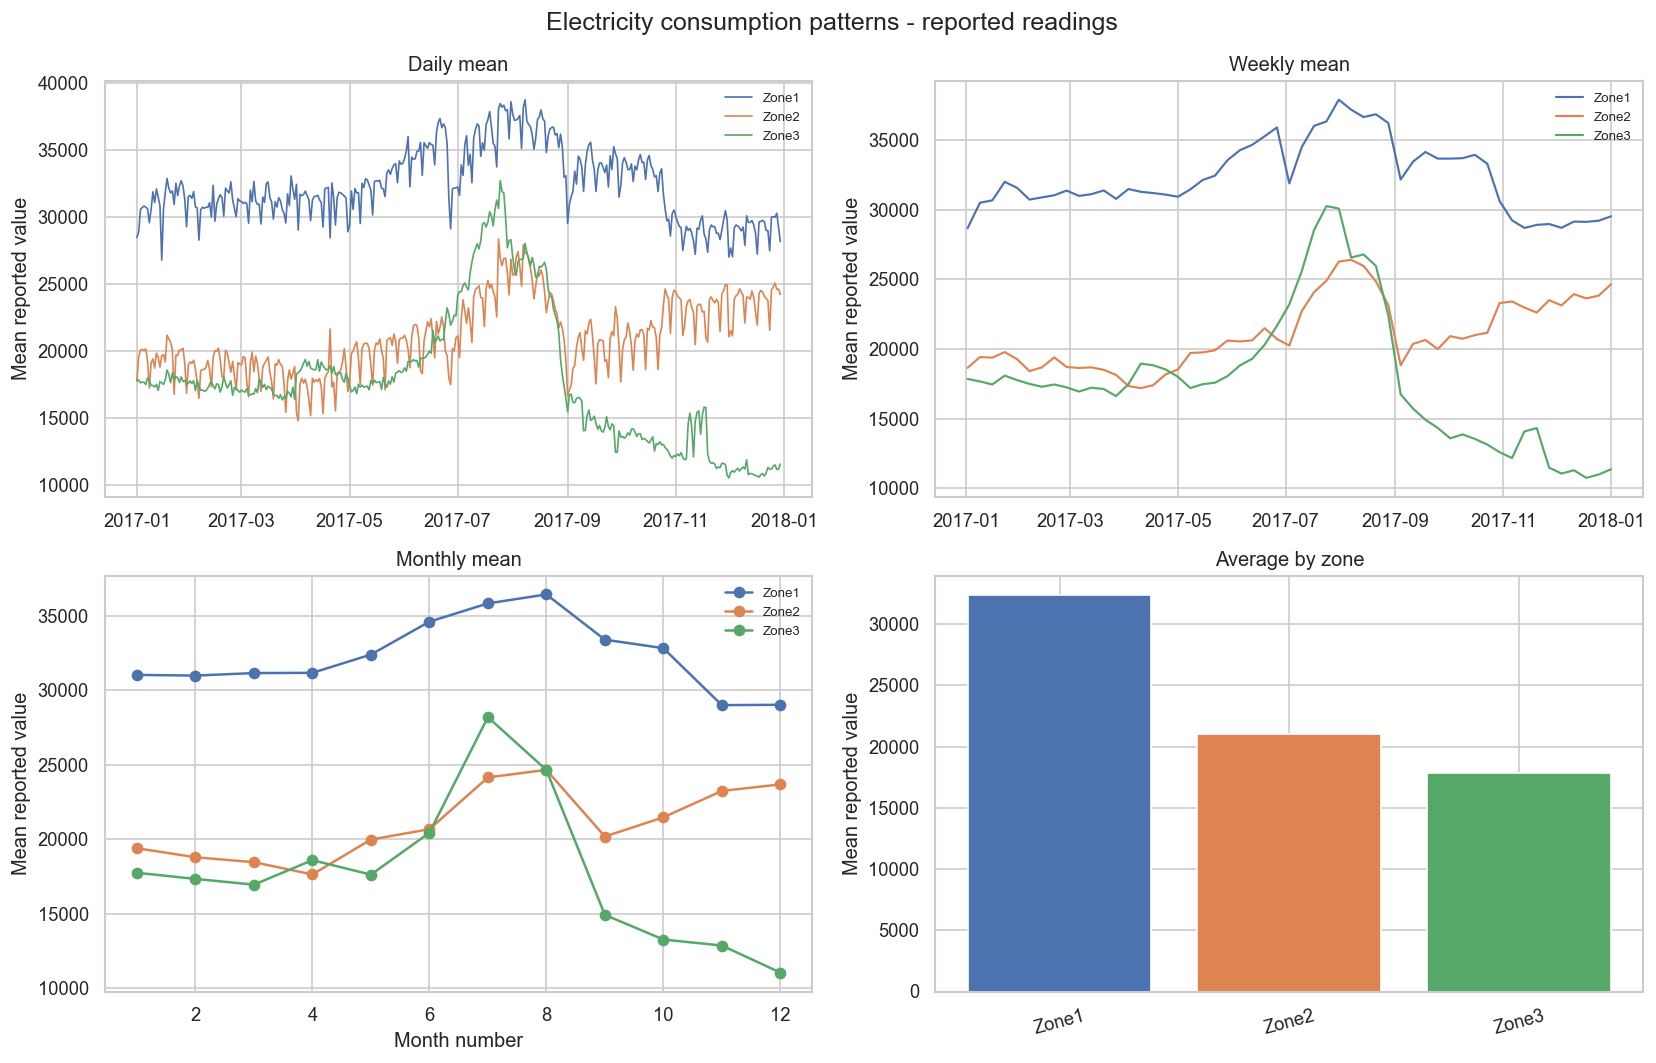

In [11]:
sns.set_theme(style="whitegrid", palette="deep")
# Matplotlib: daily, weekly, monthly trends and average by zone.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for col in zone_cols:
    axes[0,0].plot(pd.to_datetime(daily.index), daily[col], label=zone_labels[col], lw=1)
    axes[0,1].plot(weekly.index, weekly[col], label=zone_labels[col], lw=1.3)
    axes[1,0].plot(monthly.index, monthly[col], marker="o", label=zone_labels[col])
means = df[zone_cols].mean().rename(index=zone_labels).sort_values(ascending=False)
axes[1,1].bar(means.index, means.values, color=sns.color_palette("deep",3))
axes[0,0].set(title="Daily mean", ylabel="Mean reported value")
axes[0,1].set(title="Weekly mean", ylabel="Mean reported value")
axes[1,0].set(title="Monthly mean", xlabel="Month number", ylabel="Mean reported value")
axes[1,1].set(title="Average by zone", ylabel="Mean reported value")
for ax in axes.flat[:3]: ax.legend(frameon=False, fontsize=8)
axes[1,1].tick_params(axis="x", rotation=15)
fig.suptitle("Electricity consumption patterns - reported readings", fontsize=15)
fig.tight_layout(); fig.savefig(VIS_DIR/"summary_time_patterns.png",dpi=170,bbox_inches="tight"); display(fig); plt.close(fig)


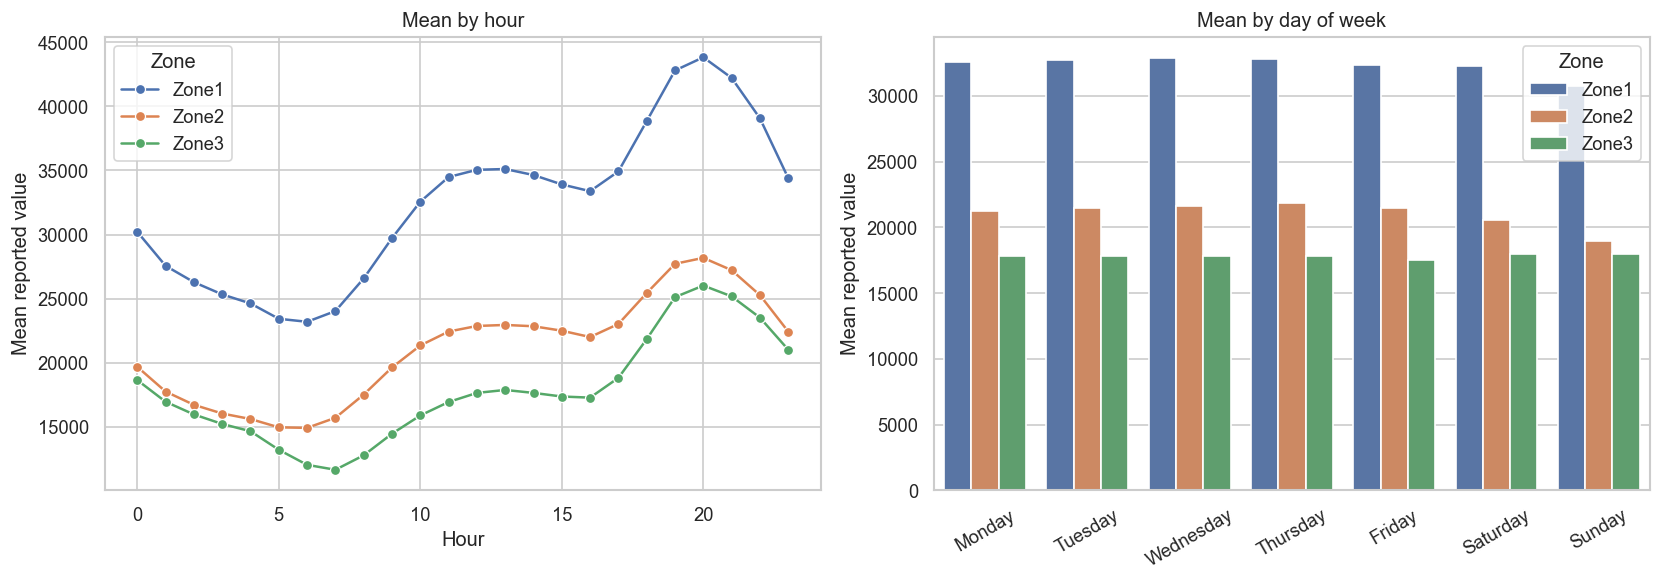

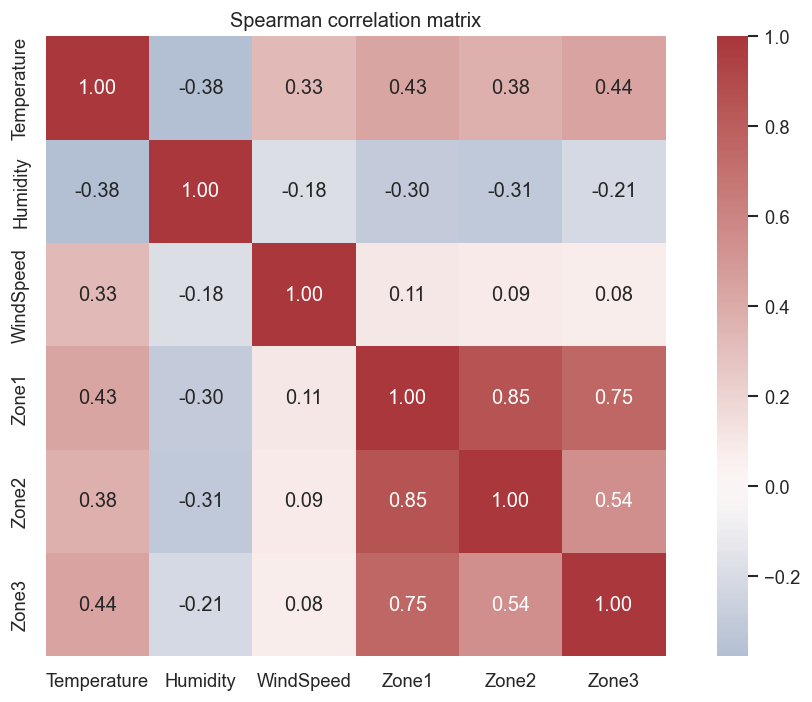

In [12]:
# Seaborn: typical hourly and day-of-week patterns plus environmental correlation heatmap.
long_time = df.melt(id_vars=["Hour","DayOfWeek"],value_vars=zone_cols,var_name="Zone",value_name="ReportedValue")
long_time["Zone"] = long_time.Zone.map(zone_labels)
fig, axes = plt.subplots(1,2,figsize=(14,5))
sns.lineplot(data=long_time,x="Hour",y="ReportedValue",hue="Zone",estimator="mean",errorbar=None,marker="o",ax=axes[0])
axes[0].set(title="Mean by hour",ylabel="Mean reported value")
long_dow = df.melt(id_vars=["DayOfWeek"],value_vars=zone_cols,var_name="Zone",value_name="ReportedValue")
long_dow["Zone"] = long_dow.Zone.map(zone_labels)
sns.barplot(data=long_dow,x="DayOfWeek",y="ReportedValue",hue="Zone",order=dow_order,errorbar=None,ax=axes[1])
axes[1].set(title="Mean by day of week",xlabel="",ylabel="Mean reported value"); axes[1].tick_params(axis="x",rotation=30)
fig.tight_layout(); fig.savefig(VIS_DIR/"hourly_weekly_patterns.png",dpi=170,bbox_inches="tight"); display(fig); plt.close(fig)

correlation_matrix = df[env_cols+zone_cols].corr(method="spearman").rename(index=zone_labels,columns=zone_labels)
fig,ax=plt.subplots(figsize=(9,6)); sns.heatmap(correlation_matrix,annot=True,fmt=".2f",cmap="vlag",center=0,square=True,ax=ax)
ax.set_title("Spearman correlation matrix"); fig.tight_layout(); fig.savefig(VIS_DIR/"spearman_correlation_heatmap.png",dpi=170,bbox_inches="tight"); display(fig); plt.close(fig)


In [13]:
# Plotly interactive daily trend and environmental relationships.
plotly_daily = px.line(daily.reset_index(),x="Date",y=zone_cols,title="Interactive daily mean reported consumption by zone",labels={"value":"Mean reported value per reading","variable":"Zone"})
plotly_daily.update_layout(template="plotly_white",legend_title="Zone")
plotly_daily.write_html(VIS_DIR/"interactive_daily_trend.html",include_plotlyjs=True)
display(plotly_daily)

plotly_week = px.line(weekly.reset_index(), x="Datetime", y=zone_cols, title="Interactive weekly mean reported consumption", labels={"value":"Mean reported value per reading","variable":"Zone","Datetime":"Week starting"})
plotly_week.update_layout(template="plotly_white")
plotly_week.write_html(VIS_DIR/"interactive_weekly_trend.html", include_plotlyjs=True)
display(plotly_week)

plotly_hourly = px.line(hourly.reset_index(), x="Hour", y=zone_cols, markers=True, title="Interactive average hourly profile", labels={"value":"Mean reported value per reading","variable":"Zone"})
plotly_hourly.update_layout(template="plotly_white")
plotly_hourly.write_html(VIS_DIR/"interactive_hourly_profile.html", include_plotlyjs=True)
display(plotly_hourly)

sample = df.iloc[::24].copy()
fig = make_subplots(rows=1,cols=3,subplot_titles=["Temperature","Humidity","Wind speed"])
for j, factor in enumerate(env_cols,1):
    for col in zone_cols:
        fig.add_trace(go.Scattergl(x=sample[factor],y=sample[col],mode="markers",name=zone_labels[col],legendgroup=zone_labels[col],showlegend=(j==1),marker={"size":4,"opacity":.4},customdata=sample.Datetime.astype(str),hovertemplate="Date=%{customdata}<br>"+factor+"=%{x:.2f}<br>Reported value=%{y:.2f}<extra>"+zone_labels[col]+"</extra>"),row=1,col=j)
    fig.update_xaxes(title_text=factor,row=1,col=j)
fig.update_yaxes(title_text="Reported value",row=1,col=1)
fig.update_layout(title="Environmental factors and reported consumption (1-in-24 display sample)",height=500,template="plotly_white",legend_title="Zone")
fig.write_html(VIS_DIR/"interactive_environment_relationships.html",include_plotlyjs=True)
display(fig)


Interactive Plotly figure saved under visualizations/

Interactive Plotly figure saved under visualizations/

Interactive Plotly figure saved under visualizations/

Interactive Plotly figure saved under visualizations/

## Task 6 - Business Insights and Recommendations

### Evidence-based findings
1. Zone 1 has the highest mean reported reading (about 32,345), followed by Zone 2 (21,043) and Zone 3 (17,835); Zone 1's mean is about 81% above Zone 3's.
2. The mean hourly profile peaks at 20:00 for all three zones. Typical lowest hours occur around 06:00-07:00.
3. Zone 1 and Zone 2 reach their highest monthly mean in August; Zone 3 peaks in July. Zone 3's monthly mean is lowest in December.
4. Weekday means exceed weekend means in Zones 1 and 2; Zone 3's weekend mean is slightly higher than its weekday mean. The effect is therefore not uniform across zones.
5. At the 10-minute level, temperature has a moderate positive Spearman association with all zones (approximately 0.38-0.44); humidity is negative (-0.21 to -0.31); wind-speed associations are weak positive (about 0.08-0.11). These are associations only.
6. The IQR rule flags 7 Zone 2 readings and 1,191 Zone 3 readings (2.27%). Zone 3 flags cluster in July-August, mainly 19:00-23:00, suggesting a temporal/seasonal regime to investigate rather than values to delete automatically.
7. Data quality checks found no missing values, duplicate rows/timestamps, numeric parse failures, negative readings, or cadence gaps within the observed range.

### Recommendations
1. Plan operational capacity and demand-response coverage around the consistent evening peak near 20:00; evaluate the impact separately by zone.
2. Prepare seasonal plans before the observed July-August peaks, and validate the seasonal shape on additional years before generalizing beyond this one-year extract.
3. Investigate Zone 3's July-August evening high readings with operational calendars, meter context, and site information; preserve flagged records until validated as errors.
4. Use temperature as a candidate input in a future forecast, then validate using out-of-time data and suitable controls; do not treat the observed correlation as a causal effect.
5. Confirm the per-reading unit interpretation and diffuse-flow definitions with the data owner before calculating energy totals, costs, or environmental impact.


## Limitations

- One observed year (2017) cannot establish year-over-year seasonality, long-term trends, or weather-response stability.
- The dataset ends on December 30, not December 31.
- The power measurement unit per 10-minute row and diffuse-flow definitions are unresolved in the supplied dictionary.
- IQR outliers are statistical flags; no readings were removed.
- Rank correlations may be affected by autocorrelation, seasonality and confounders; they are not causal estimates.
- Mean reported readings are not energy totals. No sum-based kWh claim is made.
